In [62]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [63]:
from write_pager_plots import *

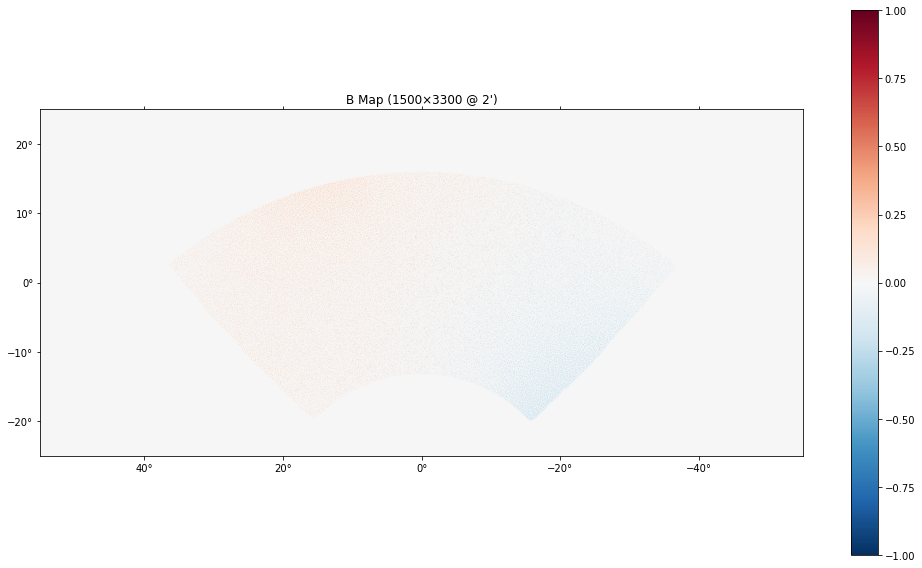

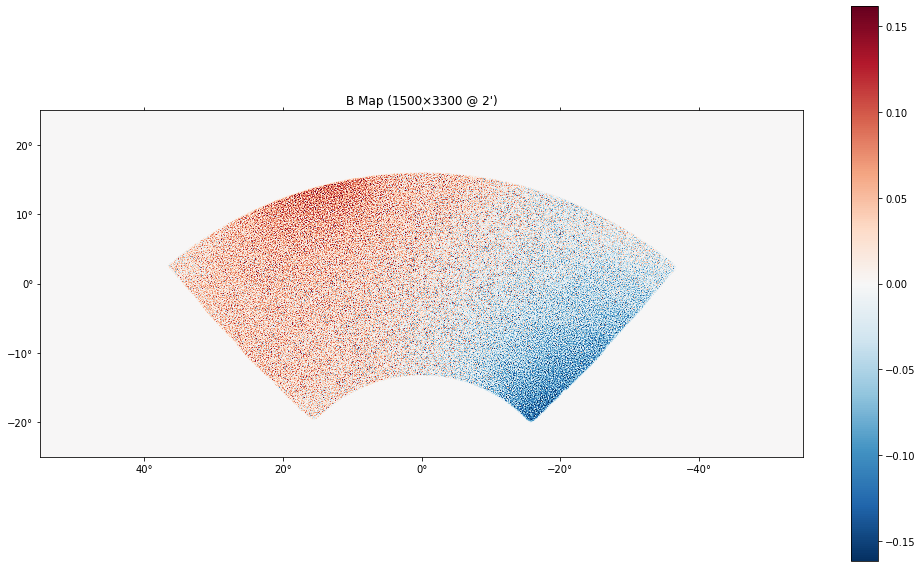

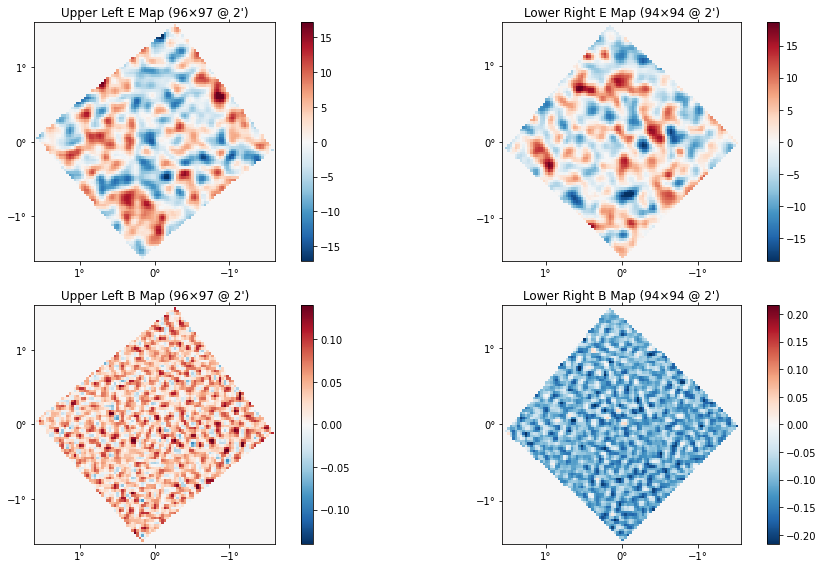

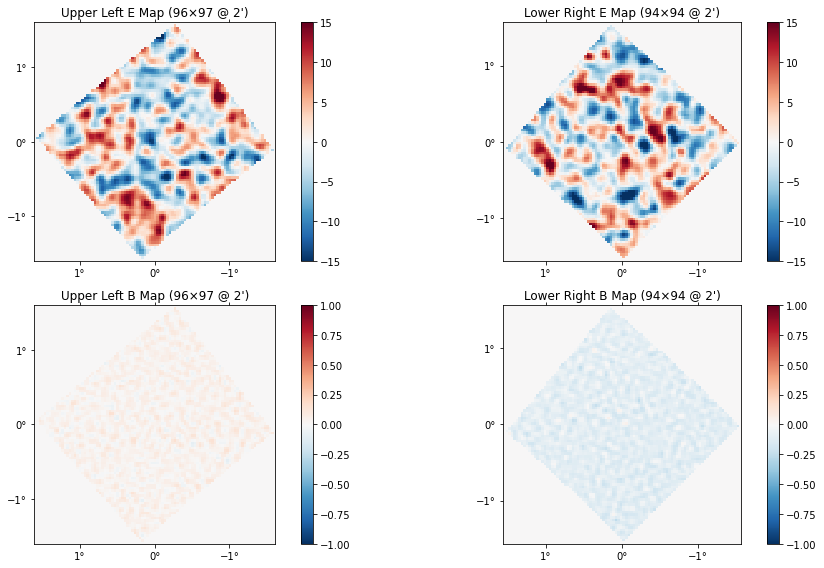

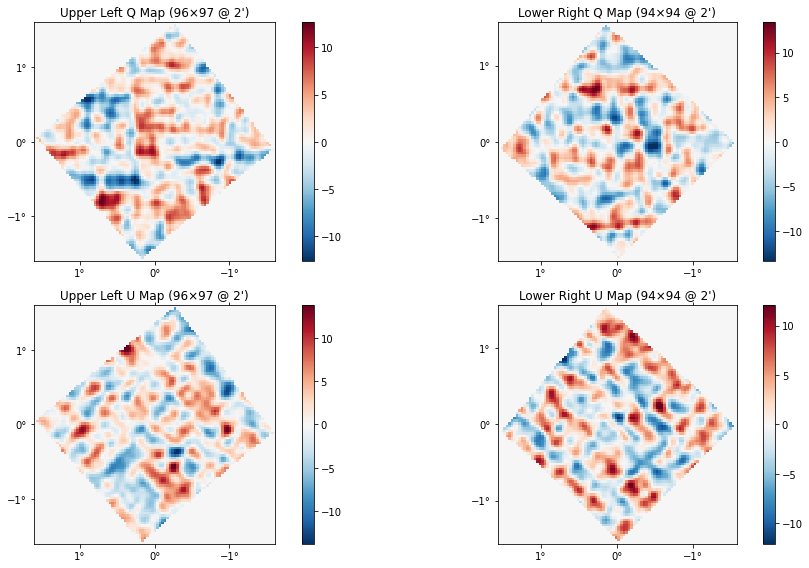

...

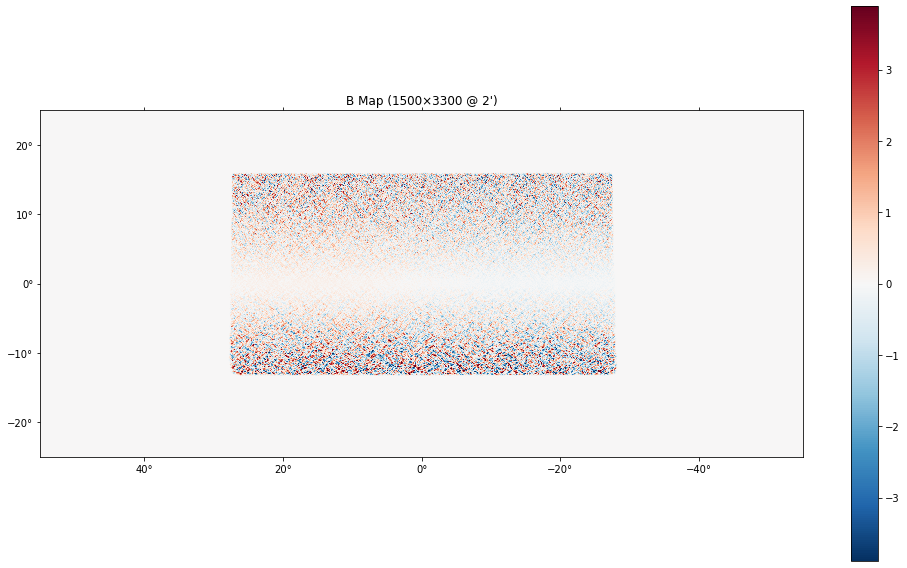

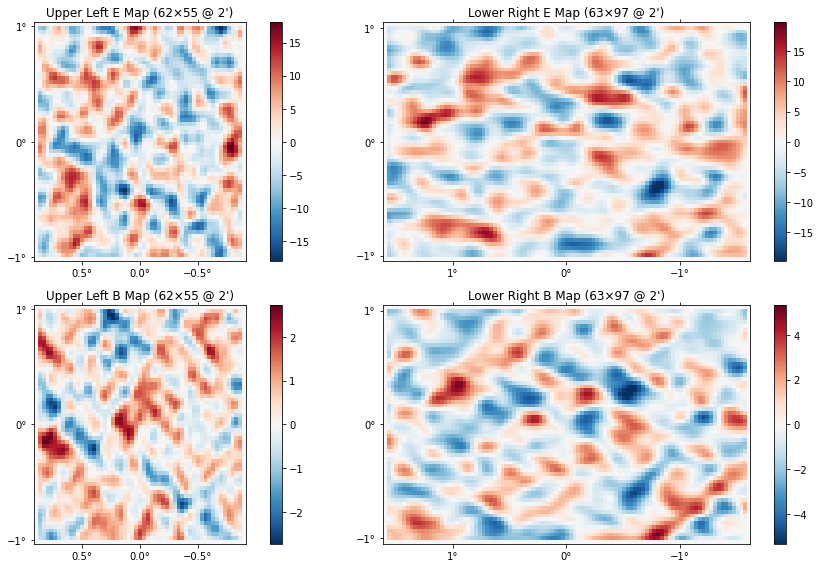

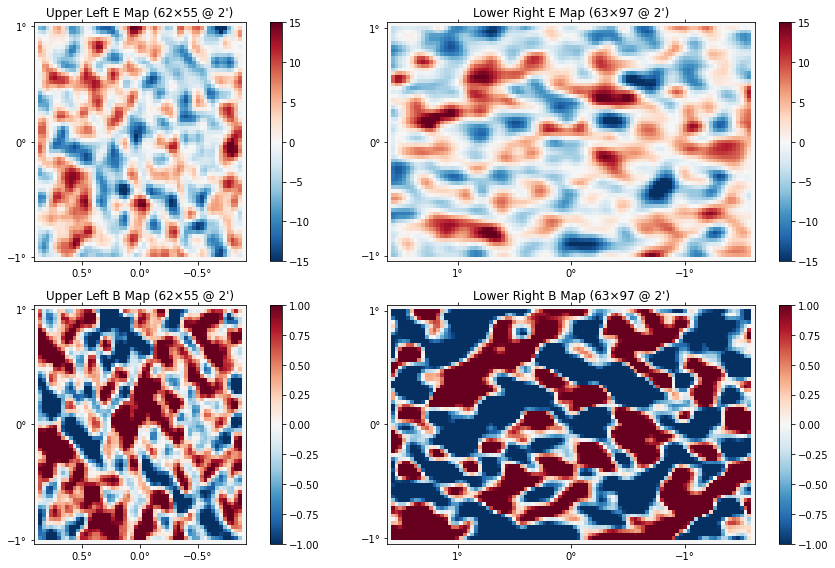

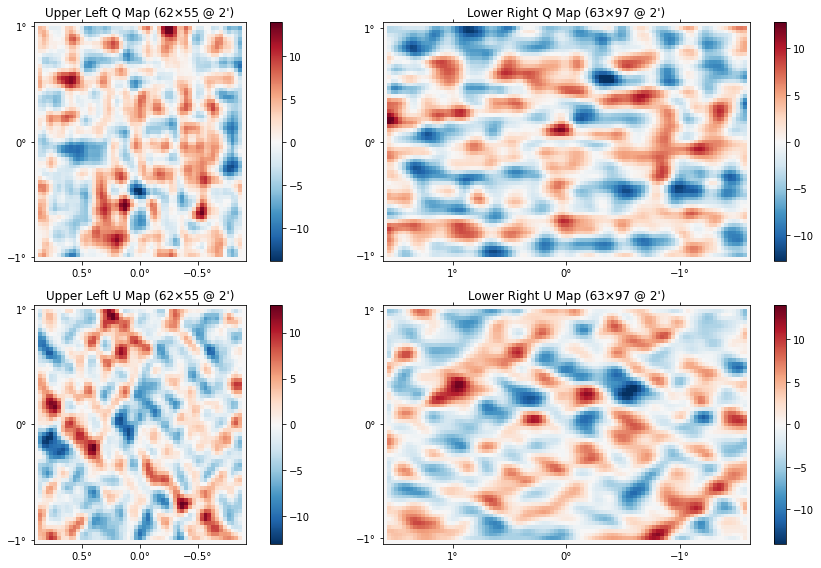

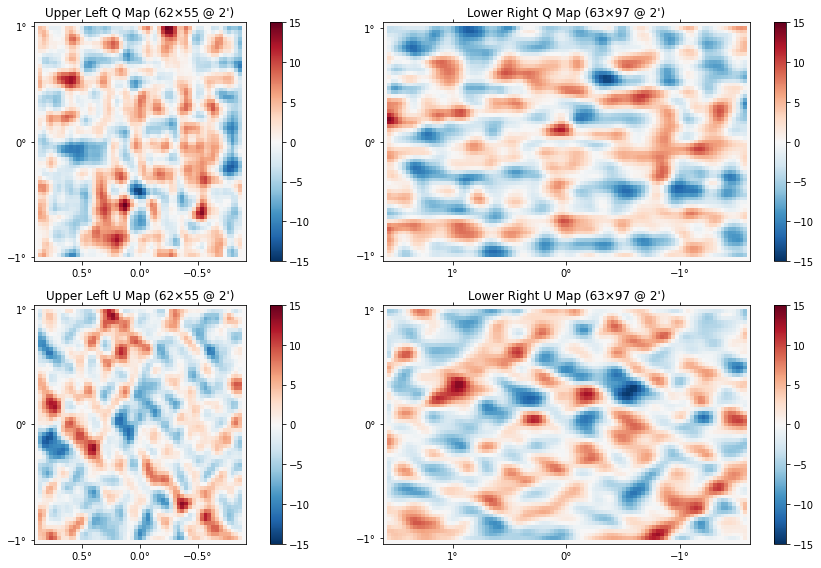

/home/cailmdaley/work/pol_project/pager/v2/write_pager_plots.py:28: RuntimeWarning: invalid value encountered in greater
  [((50 - 3.3)*G3Units.deg < ra),  (ra  < 50*G3Units.deg),
/home/cailmdaley/work/pol_project/pager/v2/write_pager_plots.py:28: RuntimeWarning: invalid value encountered in less
  [((50 - 3.3)*G3Units.deg < ra),  (ra  < 50*G3Units.deg),
/home/cailmdaley/work/pol_project/pager/v2/write_pager_plots.py:29: RuntimeWarning: invalid value encountered in greater
  ((-47.5 - 2)*G3Units.deg < dec), (dec < -47.5*G3Units.deg)]
/home/cailmdaley/work/pol_project/pager/v2/write_pager_plots.py:29: RuntimeWarning: invalid value encountered in less
  ((-47.5 - 2)*G3Units.deg < dec), (dec < -47.5*G3Units.deg)]
/home/cailmdaley/work/pol_project/pager/v2/write_pager_plots.py:32: RuntimeWarning: invalid value encountered in greater
  [(-50*G3Units.deg < ra), (ra < (-50 + 5.9)*G3Units.deg),
/home/cailmdaley/work/pol_project/pager/v2/write_pager_plots.py:32: RuntimeWarning: invalid value en

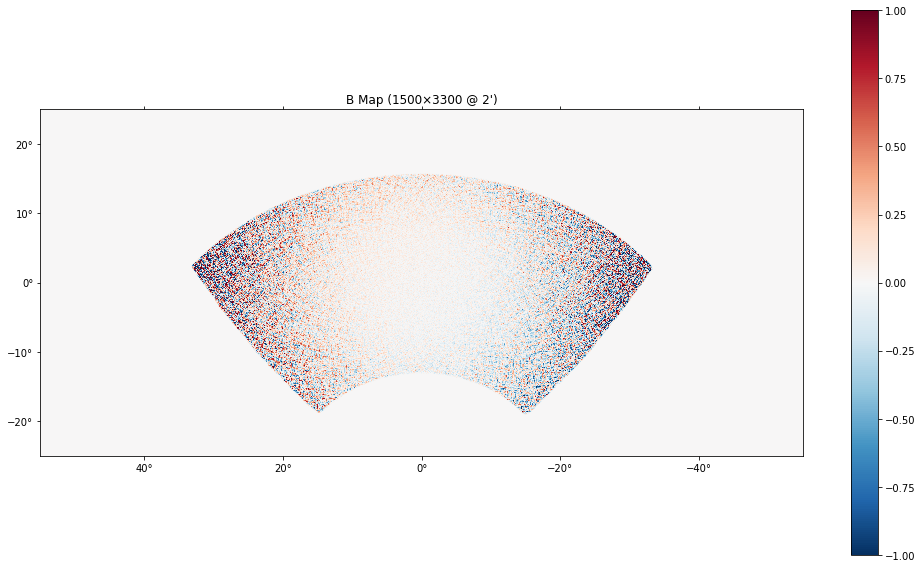

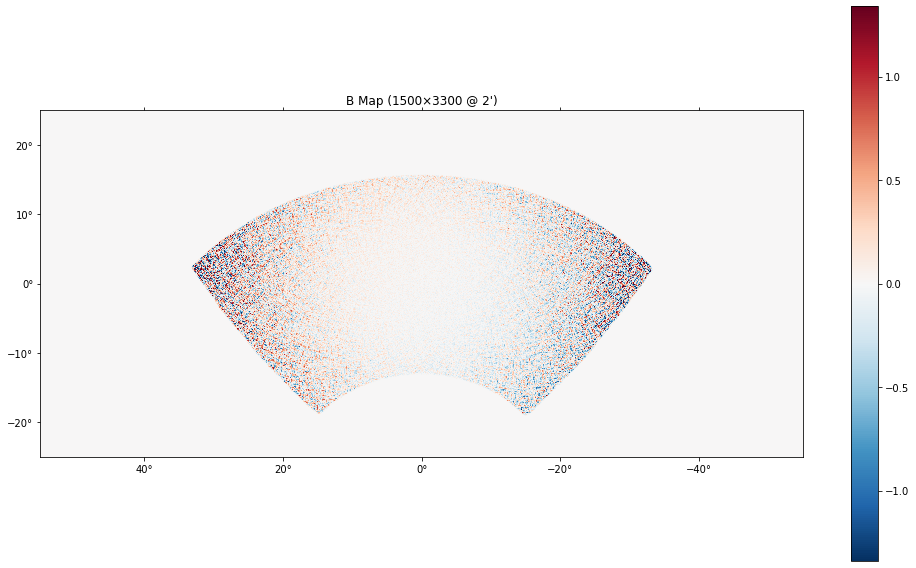

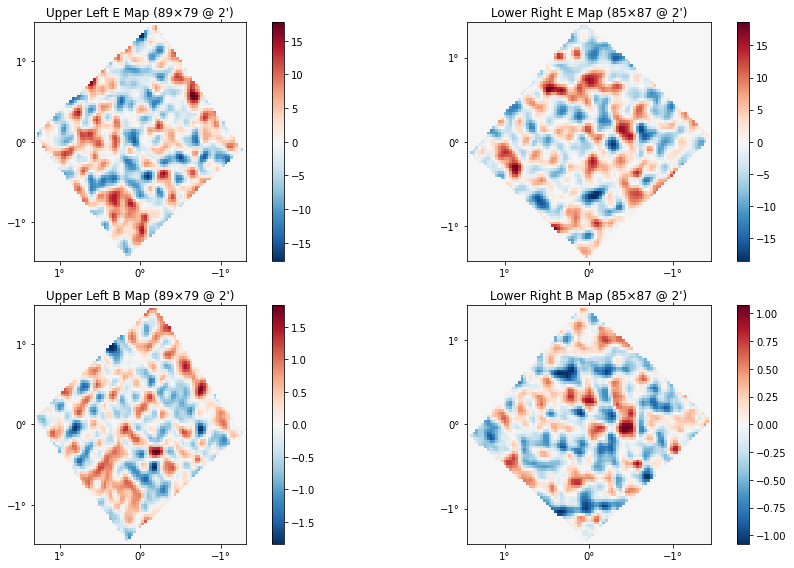

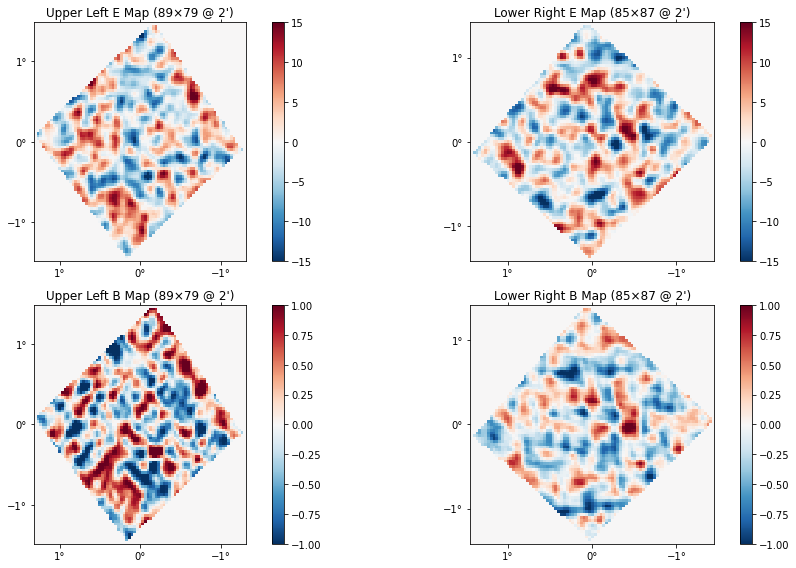

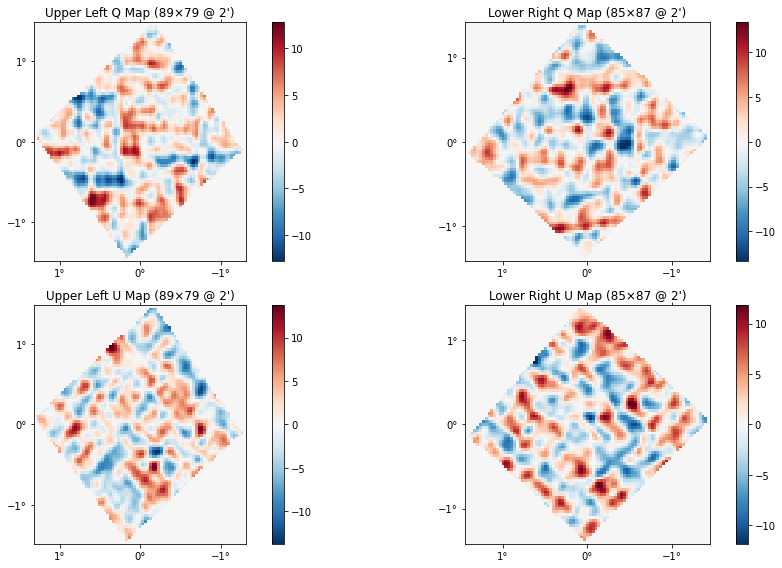

...

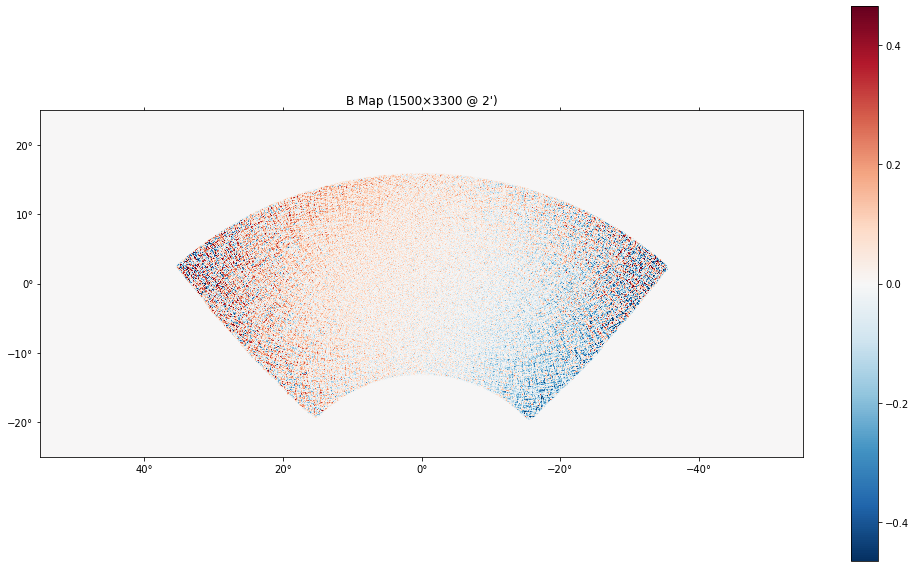

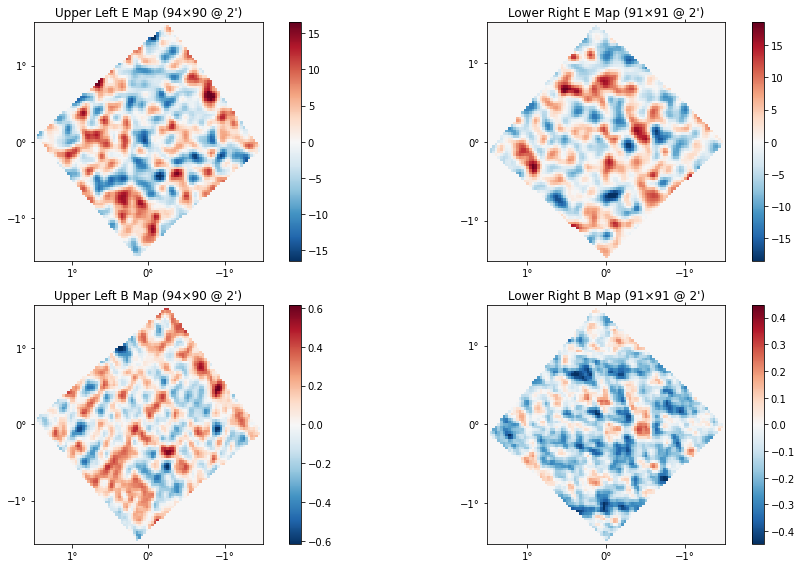

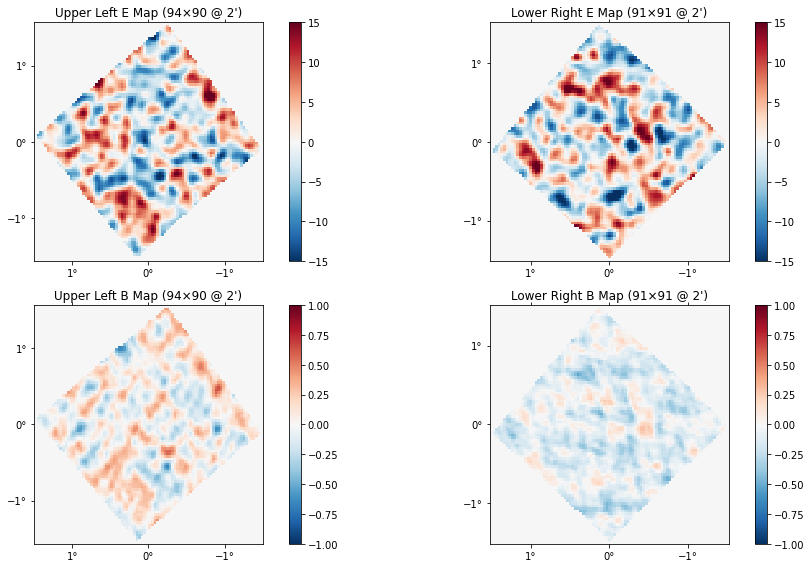

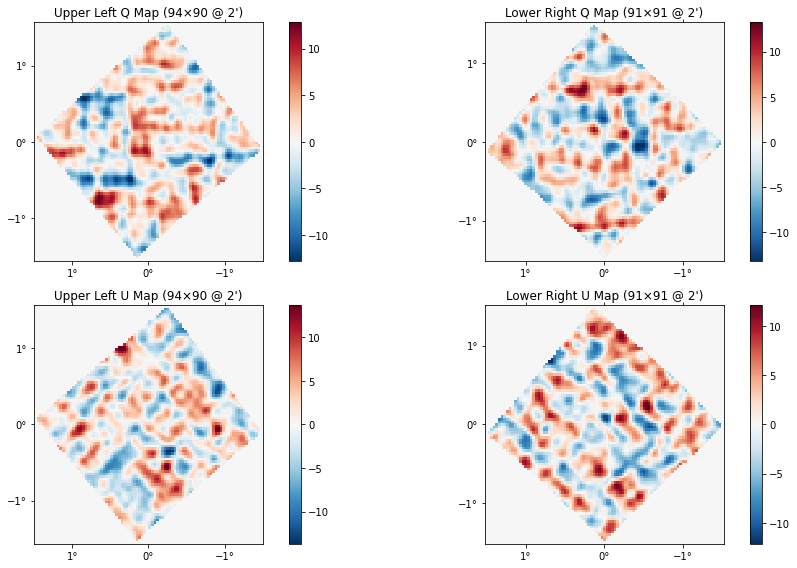

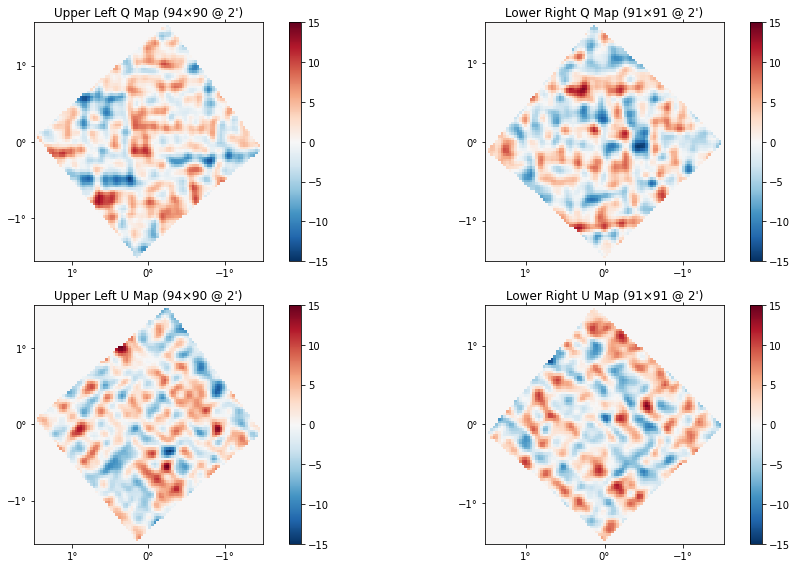

In [110]:
readdir = next(basedir.glob("*proj=5_res=2*")); readdir
for readdir in basedir.glob("lmax=*"):

    qu_frame = next(G3File(str(readdir / "seed1.g3" )))
    for k in qu_frame:
        np.asarray(qu_frame[k])[:] = np.nan_to_num(qu_frame[k])
    mask_frame = next(G3File(str(readdir / "mask.g3" )))

    plot_EB("test", qu_frame, mask_frame["T"])
    plot_QU("test", qu_frame, mask_frame["T"])
    plt.show()

In [30]:
from spt3g.maps import get_ra_dec_map

mask_frame = next(G3File(str(readdir / "mask.g3" )))
qu_frame = next(G3File(str(readdir / "seed1.g3" )))

mask = mask_frame["T"]
ra, dec = get_ra_dec_map(mask)

In [194]:
mask1_inds = np.logical_and.reduce(
    [(-50*G3Units.deg < np.asarray(ra)), (np.asarray(ra) < -50*G3Units.deg + 5*G3Units.deg / np.cos(dec)),
     (-52.5*G3Units.deg < np.asarray(dec)), (np.asarray(dec) < -47.5*G3Units.deg)]
)

mask2_inds = np.logical_and.reduce(
    [(50*G3Units.deg - 5*G3Units.deg / np.cos(dec) < np.asarray(ra)), (np.asarray(ra) < 50*G3Units.deg),
     (-70*G3Units.deg < np.asarray(dec)), (np.asarray(dec) < -65*G3Units.deg)]
)

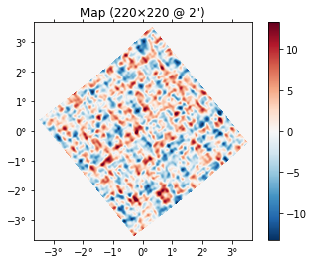

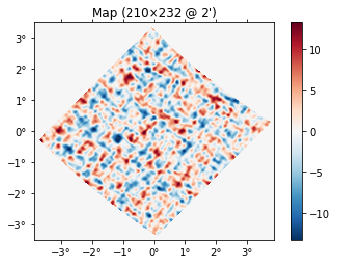

In [199]:
(ymin1, ymax1), (xmin1, xmax1) = [[int(f(np.where(mask1_inds)[i])) for f in (np.min, np.max)] for i in (0, 1)]
(ymin2, ymax2), (xmin2, xmax2) = [[int(f(np.where(mask2_inds)[i])) for f in (np.min, np.max)] for i in (0, 1)]
extrema1, extrema2
q = qu_frame["Q"].Clone(False)
pad=5
np.asarray(q)[mask1_inds] = np.asarray(qu_frame["Q"])[mask1_inds]
np.asarray(q)[mask2_inds] = np.asarray(qu_frame["Q"])[mask2_inds]
q[ymin1-pad:ymax1+pad, xmin1-pad:xmax1+pad].plot(); plt.show()
q[ymin2-pad:ymax2+pad, xmin2-pad:xmax2+pad].plot()

In [410]:
def plot_generic_inset(frame, mask, vlims):
    k1, k2  = list(frame.keys())
    
    ra, dec = get_ra_dec_map(mask)
    mask2_inds = np.logical_and.reduce(
        [(-50*G3Units.deg < np.asarray(ra)), (np.asarray(ra) < -50*G3Units.deg + 5*G3Units.deg / np.cos(dec)),
         (-52.5*G3Units.deg < np.asarray(dec)), (np.asarray(dec) < -47.5*G3Units.deg)]
    )

    mask1_inds = np.logical_and.reduce(
        [(50*G3Units.deg - 2.05*G3Units.deg / np.cos(dec) < np.asarray(ra)), (np.asarray(ra) < 50*G3Units.deg),
         (-70*G3Units.deg < np.asarray(dec)), (np.asarray(dec) < -62.21*G3Units.deg)]
    )
    
    (ymin1, ymax1), (xmin1, xmax1) = [[int(f(np.where(mask1_inds)[i])) for f in (np.min, np.max)] for i in (0, 1)]
    (ymin2, ymax2), (xmin2, xmax2) = [[int(f(np.where(mask2_inds)[i])) for f in (np.min, np.max)] for i in (0, 1)]
    
    m1, m2 = [frame[k].Clone(False) for k in frame]
    np.asarray(m1)[mask1_inds] = np.asarray(frame[k1])[mask1_inds]
    np.asarray(m1)[mask2_inds] = np.asarray(frame[k1])[mask2_inds]
    np.asarray(m2)[mask1_inds] = np.asarray(frame[k2])[mask1_inds]
    np.asarray(m2)[mask2_inds] = np.asarray(frame[k2])[mask2_inds]
    
    pad=10
    
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14,8))
    plot_FlatSkyMap(m1[ymin1-pad:ymax1+pad, xmin1-pad:xmax1+pad], 
                    vlim=vlims[0],  ax=ax1, title_prefix="Upper Left {} ".format(k1))
    plot_FlatSkyMap(m1[ymin2-pad:ymax2+pad, xmin2-pad:xmax2+pad], 
                    vlim=vlims[0],  ax=ax3, title_prefix="Lower Right {} ".format(k1))
    plot_FlatSkyMap(m2[ymin1-pad:ymax1+pad, xmin1-pad:xmax1+pad], 
                    vlim=vlims[1],  ax=ax2, title_prefix="Upper Left {} ".format(k2))
    plot_FlatSkyMap(m2[ymin2-pad:ymax2+pad, xmin2-pad:xmax2+pad], 
                    vlim=vlims[1],  ax=ax4, title_prefix="Lower Right {} ".format(k2))
    return fig


def plot_QU(writestring, qu_frame, mask):
    fig = plot_generic_inset(qu_frame, mask, ('sym', 'sym'))
    fig.savefig(writestring + "_figtype=QUinset_vlim=99th.png"); plt.close(fig)
    
    fig = plot_generic_inset(qu_frame, mask, ((-15,15), (-15,15)))
    fig.savefig(writestring + "_figtype=QUinset_vlim=fixed.png"); plt.close(fig)


def plot_EB(writestring, qu_frame, mask):
    B_fourier = constructEB(qu_frame, apod_mask=mask)["B"]

    fig, ax = plt.subplots(1, figsize=(14,8), tight_layout=True)
    plot_MapSpectrum2D(B_fourier, title_prefix="B ", ax=ax, vlim=(1e-8, 2e-2))
    fig.savefig(writestring + "_figtype=Bfourierspt_vlim=fixed.png"); plt.close(fig)

    fig, ax = plt.subplots(1, figsize=(14,8), tight_layout=True)
    plot_MapSpectrum2D(B_fourier, title_prefix="B ", ax=ax, vlim='asym')
    fig.savefig(writestring + "_figtype=Bfourierspt_vlim=99th.png"); plt.close(fig)
    del B_fourier

    eb_frame = constructEB(qu_frame)
    B_map = eb_frame["B"].get_rmap()
    np.asarray(B_map)[:] *= mask

    fig, ax = plt.subplots(1, figsize=(14,8), tight_layout=True)
    plot_FlatSkyMap(B_map, vlim=(-1,1),  ax=ax, title_prefix="B ")
    fig.savefig(writestring + "_figtype=Bmapspt_vlim=fixed.png"); plt.close(fig)

    fig, ax = plt.subplots(1, figsize=(14,8), tight_layout=True)
    plot_FlatSkyMap(B_map, vlim='sym', ax=ax, title_prefix="B ")
    fig.savefig(writestring + "_figtype=Bmapspt_vlim=99th.png"); plt.close(fig)
    del B_map
    
    fig = plot_generic_inset({k : eb_frame[k].get_rmap() for k in eb_frame}, mask, ('sym', 'sym'))
    fig.savefig(writestring + "_figtype=EBinset_vlim=99th.png"); plt.close(fig)

    
    fig = plot_generic_inset({k : eb_frame[k].get_rmap() for k in eb_frame}, mask, ((-15,15), (-1,1)))
    fig.savefig(writestring + "_figtype=EBinset_vlim=fixed.png"); plt.close(fig)

In [411]:
for readdir in dirs[1:]:
    qu_frame = next(G3File(str(readdir / "seed1.g3" )))
    mask_frame = next(G3File(str(readdir / "mask.g3" )))
    print(readdir)
    
    for k in qu_frame:
        np.asarray(qu_frame[k])[:] = np.nan_to_num(qu_frame[k])
    plot_EB("test", qu_frame, mask_frame["T"])
    plot_QU("test", qu_frame, mask_frame["T"])

/sptlocal/user/cailmdaley/pol_project/pager/v2/pager_maps_big/proj=7_res=2


<ipython-input-410-faef7763d784>:6: RuntimeWarning: invalid value encountered in less
  [(-50*G3Units.deg < np.asarray(ra)), (np.asarray(ra) < -50*G3Units.deg + 5*G3Units.deg / np.cos(dec)),
<ipython-input-410-faef7763d784>:7: RuntimeWarning: invalid value encountered in greater
  (-52.5*G3Units.deg < np.asarray(dec)), (np.asarray(dec) < -47.5*G3Units.deg)]
<ipython-input-410-faef7763d784>:7: RuntimeWarning: invalid value encountered in less
  (-52.5*G3Units.deg < np.asarray(dec)), (np.asarray(dec) < -47.5*G3Units.deg)]
<ipython-input-410-faef7763d784>:11: RuntimeWarning: invalid value encountered in less
  [(50*G3Units.deg - 2.05*G3Units.deg / np.cos(dec) < np.asarray(ra)), (np.asarray(ra) < 50*G3Units.deg),
<ipython-input-410-faef7763d784>:12: RuntimeWarning: invalid value encountered in greater
  (-70*G3Units.deg < np.asarray(dec)), (np.asarray(dec) < -62.21*G3Units.deg)]
<ipython-input-410-faef7763d784>:12: RuntimeWarning: invalid value encountered in less
  (-70*G3Units.deg < np.a

/sptlocal/user/cailmdaley/pol_project/pager/v2/pager_maps_big/proj=4_res=2
/sptlocal/user/cailmdaley/pol_project/pager/v2/pager_maps_big/proj=5_res=2
/sptlocal/user/cailmdaley/pol_project/pager/v2/pager_maps_big/proj=9_res=2
/sptlocal/user/cailmdaley/pol_project/pager/v2/pager_maps_big/proj=2_res=2


<ipython-input-410-faef7763d784>:6: RuntimeWarning: invalid value encountered in greater
  [(-50*G3Units.deg < np.asarray(ra)), (np.asarray(ra) < -50*G3Units.deg + 5*G3Units.deg / np.cos(dec)),


/sptlocal/user/cailmdaley/pol_project/pager/v2/pager_maps_big/proj=3_res=2
/sptlocal/user/cailmdaley/pol_project/pager/v2/pager_maps_big/proj=0_res=2
/sptlocal/user/cailmdaley/pol_project/pager/v2/pager_maps_big/proj=1_res=2


In [125]:
np.where(mask1_inds)[0]

array([580, 580, 581, ..., 949, 950, 950])

In [126]:
len(np.ravel(ra)), len(mask1_inds)

(4950000, 1500)

In [117]:
mask1_inds

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]])

In [145]:
qu_frame = next(G3File("/sptlocal/user/cailmdaley/pager_maps/nside=8192_interp=True_rebin=1_proj=ProjZEA_res=2_dec=-57.5_rotate=flat/seed1.g3"))

In [3]:
spt_mask = load_pickle("/spt/user/ddutcher/masks/3band_res2_bundle_apod_mask.pkl")

In [163]:
def plot_generic_inset(frame, vlims):
    k1, k2 = list(frame.keys())
    fac = 2*G3Units.arcmin / frame[k1].res
    scale = lambda ind: int(ind*fac)
    
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14,8), tight_layout=True)
    plot_FlatSkyMap(frame[k1][scale(200):scale(300), scale(625):scale(725)], vlim=vlims[0],  ax=ax1, title_prefix="Upper Left {} ".format(k1))
    plot_FlatSkyMap(frame[k1][scale(750):scale(850), -scale(200):-scale(100)], vlim=vlims[0],  ax=ax3, title_prefix="Lower Right {} ".format(k1))
    plot_FlatSkyMap(frame[k2][scale(200):scale(300), scale(625):scale(725)], vlim=vlims[1],  ax=ax2, title_prefix="Upper Left {} ".format(k2))
    plot_FlatSkyMap(frame[k2][scale(750):scale(850), -scale(200):-scale(100)], vlim=vlims[1],  ax=ax4, title_prefix="Lower Right {} ".format(k2))
    return fig
    

def plot_QU(writestring, qu_frame):
    fig = plot_generic_inset(qu_frame, ('sym', 'sym'))
    fig.savefig(writestring + "_figtype=QUinset_vlim=99th.png"); plt.close(fig)
    
    fig = plot_generic_inset(qu_frame, ((-15,15), (-15,15)))
    fig.savefig(writestring + "_figtype=QUinset_vlim=fixed.png"); plt.close(fig)

plot_QUinset("test", qu_frame)

In [166]:
def plot_EB(writestring, qu_frame):
    mask = zoom(spt_mask, 2*G3Units.arcmin / qu_frame["Q"].res)
    B_fourier = constructEB(qu_frame, apod_mask=mask)["B"]

    fig, ax = plt.subplots(1, figsize=(14,8), tight_layout=True)
    plot_MapSpectrum2D(B_fourier, title_prefix="B ", ax=ax, vlim=(1e-8, 2e-2))
    fig.savefig(writestring + "_figtype=Bfourierspt_vlim=fixed.png"); plt.close(fig)

    fig, ax = plt.subplots(1, figsize=(14,8), tight_layout=True)
    plot_MapSpectrum2D(B_fourier, title_prefix="B ", ax=ax, vlim='asym')
    fig.savefig(writestring + "_figtype=Bfourierspt_vlim=99th.png"); plt.close(fig)
    del B_fourier

    eb_frame = constructEB(qu_frame)
    B_map = eb_frame["B"].get_rmap()
    np.asarray(B_map)[:] *= mask

    fig, ax = plt.subplots(1, figsize=(14,8), tight_layout=True)
    plot_FlatSkyMap(B_map, vlim=(-1,1),  ax=ax, title_prefix="B ")
    fig.savefig(writestring + "_figtype=Bmapspt_vlim=fixed.png"); plt.close(fig)

    fig, ax = plt.subplots(1, figsize=(14,8), tight_layout=True)
    plot_FlatSkyMap(B_map, vlim='sym', ax=ax, title_prefix="B ")
    fig.savefig(writestring + "_figtype=Bmapspt_vlim=99th.png"); plt.close(fig)
    del B_map
    
    fig = plot_generic_inset({k : eb_frame[k].get_rmap() for k in eb_frame}, ('sym', 'sym'))
    fig.savefig(writestring + "_figtype=EBinset_vlim=99th.png"); plt.close(fig)

    
    fig = plot_generic_inset({k : eb_frame[k].get_rmap() for k in eb_frame}, ((-15,15), (-1,1)))
    fig.savefig(writestring + "_figtype=EBinset_vlim=fixed.png"); plt.close(fig)
    

plot_EB('test', qu_frame)

In [167]:
readpath = pathlib.Path("/sptlocal/user/cailmdaley/pager_maps/")
writepath = pathlib.Path("/home/cailmdaley/public/html/projection_pager/pager_plots/v3")
def write_plots(writepath, dirs):
    writepath.mkdir(exist_ok=True)
    for readdir in tqdm(list(dirs)):
        writestring = str(writepath / readdir.name)
        frame_path = readdir / "seed1.g3" 
        if frame_path.exists():
            qu_frame = next(G3File(str(frame_path)))
        else:
            pass

        plot_EB(writestring, qu_frame)
        plot_QU(writestring, qu_frame)
        del qu_frame

In [178]:
write_plots(writepath, readpath.glob("*nside=8192*rebin=1*proj=ProjZEA*res=2*"))

12it [02:38, 13.20s/it]


In [175]:
len(list(readpath.glob("*nside=8192*rebin=1*proj=ProjZEA*res=2*")))

12

In [181]:
print(list(readpath.glob("*nside=8192*rebin=1*proj=ProjZEA*res=2*"))

[PosixPath('/sptlocal/user/cailmdaley/pager_maps/nside=8192_interp=False_rebin=1_proj=ProjZEA_res=2_dec=0_rotate=None'), PosixPath('/sptlocal/user/cailmdaley/pager_maps/nside=8192_interp=True_rebin=1_proj=ProjZEA_res=2_dec=0_rotate=None'), PosixPath('/sptlocal/user/cailmdaley/pager_maps/nside=8192_interp=False_rebin=1_proj=ProjZEA_res=2_dec=-57.5_rotate=None'), PosixPath('/sptlocal/user/cailmdaley/pager_maps/nside=8192_interp=True_rebin=1_proj=ProjZEA_res=2_dec=-57.5_rotate=None'), PosixPath('/sptlocal/user/cailmdaley/pager_maps/nside=8192_interp=True_rebin=1_proj=ProjZEA_res=2_dec=90.0_rotate=None'), PosixPath('/sptlocal/user/cailmdaley/pager_maps/nside=8192_interp=False_rebin=1_proj=ProjZEA_res=2_dec=90.0_rotate=None'), PosixPath('/sptlocal/user/cailmdaley/pager_maps/nside=8192_interp=False_rebin=1_proj=ProjZEA_res=2_dec=90.0_rotate=flat'), PosixPath('/sptlocal/user/cailmdaley/pager_maps/nside=8192_interp=True_rebin=1_proj=ProjZEA_res=2_dec=90.0_rotate=flat'), PosixPath('/sptlocal/us